# Capstone · Stage 2 — Live market dynamics for Kestrel Bay Capital

*Skill from Part 2: act on live data with clear triggers, inside the client's risk limits.*

Stage 1 found a calm year: a −2.9% maximum drawdown never tested the client's 10% limit. This stage asks the harder questions:

1. **Replay the year week by week** under three ways of managing the portfolio, using only information available at the time → `figures/s2_table_replay.tex`, `figures/s2_fig_replay.pdf`
2. **5,000 simulated years** from the same market model: how often would each approach breach the 10% drawdown limit or miss the 6% target? → `figures/s2_table_mc.tex`, `figures/s2_fig_mc.pdf`
3. **Rate scenarios**: portfolio impact of a rate shock using the *true* sensitivities built into the generator vs the ones *estimated* in Stage 1 → `figures/s2_table_rates.tex`

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "src")
from generate_data import SECTORS, SECTOR_PARAMS          # the true model behind the synthetic market
from portfolio_simulation import (ASSETS, VIX_SWITCH_ON, make_risk_off_weights, run_policy,
                                  simulate_years, yearly_metrics)   # shared with Stage 3

DATA_DIR, FIGURES_DIR = Path("data"), Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)
WEEKS_PER_YEAR = 52

client_profile = json.loads((DATA_DIR / "client_profile.json").read_text())
market = pd.read_csv(DATA_DIR / "market_weekly.csv")
sector_returns = market[[f"{sector} (%)" for sector in SECTORS]].to_numpy()   # (weeks, sectors), weekly %
TARGET_WEIGHTS = np.array([client_profile["allocation_pct"][asset] for asset in ASSETS], dtype=float) / 100

POLICY_COLORS = {"Buy and hold": "#2a78d6", "Monthly rebalance": "#eb6834", "Rebalance + risk triggers": "#1baf7a"}
POLICIES = list(POLICY_COLORS)
TEXT_COLOR, MUTED_COLOR, NAVY = "#222222", "#666666", "#0A2A6B"
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#BBBBBB", "xtick.color": MUTED_COLOR, "ytick.color": MUTED_COLOR})


def to_latex_number(value, number_format="{:.1f}", show_sign=False):
    """Format a number for a LaTeX table, using a proper minus sign."""
    if show_sign:
        number_format = "{:+" + number_format[2:]
    return number_format.format(value).replace("-", r"\textminus{}")

## The three approaches

| Approach | Rule |
|---|---|
| **Buy and hold** | Set the allocation once and let it drift. |
| **Monthly rebalance** | Every 4 weeks, trade back to the target allocation. |
| **Rebalance + risk triggers** | Monthly rebalance, plus a *risk-off* mode. It switches on when last week's VIX was above 20 **or** the portfolio is more than 5% below its peak, and switches off when VIX is back below 17 and the drawdown is under 3%. |

Risk-off allocation: Technology 35→27, Renewable Energy 15→13, Healthcare 15→20, Cash 15→20. It stays inside the client's
constraints: cash at most 20%, no sector above 40%. Every trade costs 5 bp of the amount traded. Decisions use **last week's**
data only, so there is no look-ahead.

In [2]:
# The rule settings, run_policy() and yearly_metrics() live in src/portfolio_simulation.py (shared with Stage 3)
RISK_OFF_WEIGHTS = make_risk_off_weights(TARGET_WEIGHTS)
asset_position = {asset: i for i, asset in enumerate(ASSETS)}
assert abs(RISK_OFF_WEIGHTS.sum() - 1) < 1e-12                       # fully invested
assert RISK_OFF_WEIGHTS[asset_position["Cash"]] <= 0.20               # client rule: cash at most 20%
assert RISK_OFF_WEIGHTS.max() <= 0.40                                 # client rule: no sector above 40%
pd.DataFrame({"Normal (%)": 100 * TARGET_WEIGHTS, "Risk-off (%)": 100 * RISK_OFF_WEIGHTS}, index=ASSETS).round(1)

,Normal (%),Risk-off (%)
Technology,35.0,27.0
Healthcare,15.0,20.0
Financials,10.0,10.0
Energy,0.0,0.0
Renewable Energy,15.0,13.0
Real Estate,10.0,10.0
Cash,15.0,20.0


## 1. Replay of the actual year

In [3]:
# The real year is a batch of one simulated year
one_year_returns = sector_returns[None]
one_year_rate = market["policy_rate_pct"].to_numpy()[None]
one_year_vix = market["vix"].to_numpy()[None]

replay_returns, replay_risk_off_weeks, replay_rows = {}, {}, {}
for policy in POLICIES:
    weekly_returns, risk_off_flags, turnover = run_policy(one_year_returns, one_year_rate, one_year_vix, policy,
                                                       TARGET_WEIGHTS, RISK_OFF_WEIGHTS)
    annual_return, annual_volatility, max_drawdown = yearly_metrics(weekly_returns)
    replay_returns[policy] = weekly_returns[0]
    replay_risk_off_weeks[policy] = risk_off_flags[0]
    replay_rows[policy] = {
        "Return (%)": annual_return[0],
        "Volatility (%)": annual_volatility[0],
        "Max drawdown (%)": max_drawdown[0],
        "Return / volatility": annual_return[0] / annual_volatility[0],
        "Turnover (x portfolio)": turnover[0],
        "Weeks in risk-off": risk_off_flags[0].sum(),
    }
replay_summary = pd.DataFrame(replay_rows).T
replay_summary.round(2)

,Return (%),Volatility (%),Max drawdown (%),Return / volatility,Turnover (x portfolio),Weeks in risk-off
Buy and hold,16.30,9.04,-2.99,1.80,0.00,0.0
Monthly rebalance,16.32,8.82,-2.95,1.85,0.25,0.0
Rebalance + risk triggers,16.02,8.66,-2.67,1.85,1.04,8.0


In [4]:
table_lines = [r"\begin{tabular}{@{}lrrrrr@{}}", r"\toprule",
               r"\textbf{Approach} & \textbf{Return} & \textbf{Volatility} & \textbf{Max drawdown} & \textbf{Turnover} & \textbf{Weeks risk-off} \\",
               r"\midrule"]
for policy, row in replay_summary.iterrows():
    cells = [
        to_latex_number(row["Return (%)"], show_sign=True) + r"\%",
        to_latex_number(row["Volatility (%)"]) + r"\%",
        to_latex_number(row["Max drawdown (%)"]) + r"\%",
        f"{row['Turnover (x portfolio)']:.2f}" + r"$\times$",
        f"{int(row['Weeks in risk-off'])}",
    ]
    table_lines.append(f"{policy} & " + " & ".join(cells) + r" \\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
latex_table = "\n".join(table_lines)
(FIGURES_DIR / "s2_table_replay.tex").write_text(latex_table)
print(latex_table)

\begin{tabular}{@{}lrrrrr@{}}
\toprule
\textbf{Approach} & \textbf{Return} & \textbf{Volatility} & \textbf{Max drawdown} & \textbf{Turnover} & \textbf{Weeks risk-off} \\
\midrule
Buy and hold & +16.3\% & 9.0\% & \textminus{}3.0\% & 0.00$\times$ & 0 \\
Monthly rebalance & +16.3\% & 8.8\% & \textminus{}3.0\% & 0.25$\times$ & 0 \\
Rebalance + risk triggers & +16.0\% & 8.7\% & \textminus{}2.7\% & 1.04$\times$ & 8 \\
\bottomrule
\end{tabular}


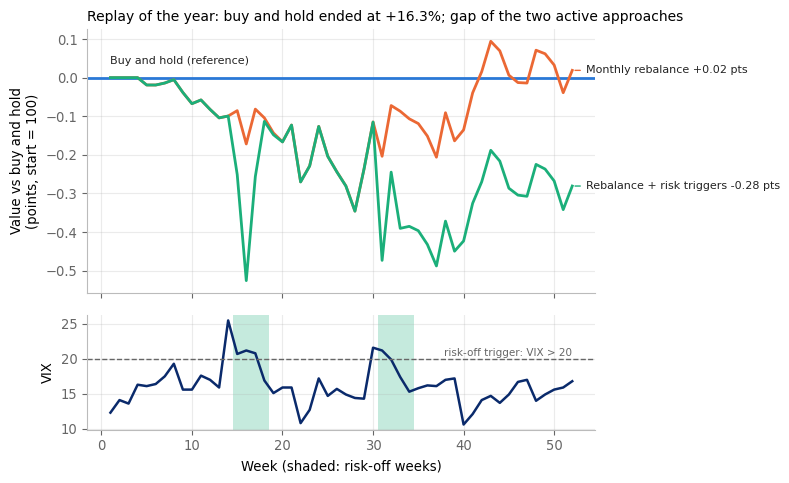

In [5]:
weeks = market["week"].to_numpy()
last_week = weeks[-1]
fig, (gap_ax, vix_ax) = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True, gridspec_kw={"height_ratios": [2.3, 1]})

# Top: how far each active approach ends up from buy and hold (the three lines overlap if plotted directly)
buy_and_hold_value = 100 * np.cumprod(1 + replay_returns["Buy and hold"] / 100)
gap_ax.axhline(0, color=POLICY_COLORS["Buy and hold"], lw=2)
gap_ax.text(1, 0.03, "Buy and hold (reference)", fontsize=8, color=TEXT_COLOR, va="bottom")
for policy in POLICIES[1:]:
    value_gap = 100 * np.cumprod(1 + replay_returns[policy] / 100) - buy_and_hold_value
    gap_ax.plot(weeks, value_gap, color=POLICY_COLORS[policy], lw=2)
    gap_ax.annotate(f"{policy} {value_gap[-1]:+.2f} pts", (last_week, value_gap[-1]),
                    xytext=(last_week + 1.5, value_gap[-1]), fontsize=8, color=TEXT_COLOR, va="center",
                    annotation_clip=False, arrowprops=dict(arrowstyle="-", color=POLICY_COLORS[policy], lw=1))
gap_ax.set_ylabel("Value vs buy and hold\n(points, start = 100)")
gap_ax.grid(alpha=0.25)
gap_ax.set_title(f"Replay of the year: buy and hold ended at {buy_and_hold_value[-1] - 100:+.1f}%; "
                 "gap of the two active approaches", loc="left", fontsize=10)

# Bottom: VIX, the trigger level, and the weeks spent in risk-off
vix_ax.plot(weeks, market["vix"], color=NAVY, lw=1.8)
vix_ax.axhline(VIX_SWITCH_ON, color=MUTED_COLOR, ls="--", lw=1)
vix_ax.text(last_week, VIX_SWITCH_ON + 0.4, f"risk-off trigger: VIX > {VIX_SWITCH_ON}", fontsize=7.5,
            color=MUTED_COLOR, ha="right")
for week_position in np.where(replay_risk_off_weeks["Rebalance + risk triggers"])[0]:
    vix_ax.axvspan(weeks[week_position] - 0.5, weeks[week_position] + 0.5,
                   color=POLICY_COLORS["Rebalance + risk triggers"], alpha=0.25, lw=0)
vix_ax.set_ylabel("VIX")
vix_ax.set_xlabel("Week (shaded: risk-off weeks)")
vix_ax.grid(alpha=0.25)

fig.subplots_adjust(right=0.76, hspace=0.12)
fig.savefig(FIGURES_DIR / "s2_fig_replay.pdf", bbox_inches="tight")
plt.show()

## 2. 5,000 simulated years

One year is one draw. To judge the *rules* rather than the luck of the year, I simulate 5,000 years from the same model
(`SECTOR_PARAMS` from the generator), with random events instead of the scripted ones:
- **Stress jumps:** each week has an 8% chance of a VIX jump of about +8 points.
- **Rate moves:** each week has a 6% chance of a ±25 bp move, keeping the rate between 1% and 6%.
- **Sector shocks:** each week has a 3% chance of a ±4% shock to one random sector.

In [6]:
N_SIMULATED_YEARS = 5000
# simulate_years() is in src/portfolio_simulation.py (shared with Stage 3)
simulated_returns, simulated_rates, simulated_vix = simulate_years(N_SIMULATED_YEARS)
simulation_results = {}
for policy in POLICIES:
    weekly_returns, _, turnover = run_policy(simulated_returns, simulated_rates, simulated_vix, policy,
                                        TARGET_WEIGHTS, RISK_OFF_WEIGHTS)
    annual_return, _, max_drawdown = yearly_metrics(weekly_returns)
    simulation_results[policy] = {"annual_return": annual_return, "max_drawdown": max_drawdown, "turnover": turnover}


def summarise(results):
    annual_return, max_drawdown = results["annual_return"], results["max_drawdown"]
    worst_5pct_years = annual_return <= np.quantile(annual_return, 0.05)
    return {
        "Median return (%)": np.median(annual_return),
        "Chance of missing 6% target (%)": 100 * (annual_return < 6).mean(),
        "Median max drawdown (%)": np.median(max_drawdown),
        "Chance of breaching 10% drawdown (%)": 100 * (max_drawdown < -10).mean(),
        "Worst 5% of years: avg return (%)": annual_return[worst_5pct_years].mean(),
        "Median turnover (x)": np.median(results["turnover"]),
    }


simulation_summary = pd.DataFrame({policy: summarise(results) for policy, results in simulation_results.items()}).T
simulation_summary.round(2)

,Median return (%),Chance of missing 6% target (%),Median max drawdown (%),Chance of breaching 10% drawdown (%),Worst 5% of years: avg return (%),Median turnover (x)
Buy and hold,13.26,21.18,-5.75,6.22,-4.00,0.00
Monthly rebalance,13.33,20.76,-5.64,5.84,-3.97,0.24
Rebalance + risk triggers,12.25,23.64,-5.58,4.22,-4.06,1.13


In [7]:
table_lines = [r"\begin{tabular}{@{}lrrrrr@{}}", r"\toprule",
               r"\textbf{Approach} & \textbf{Median} & \textbf{Chance of} & \textbf{Median max} & \textbf{Chance of} & \textbf{Worst 5\% of} \\",
               r" & \textbf{return} & \textbf{return $<$ 6\%} & \textbf{drawdown} & \textbf{drawdown $>$ 10\%} & \textbf{years (avg)} \\",
               r"\midrule"]
for policy, row in simulation_summary.iterrows():
    cells = [
        to_latex_number(row["Median return (%)"], show_sign=True) + r"\%",
        f"{row['Chance of missing 6% target (%)']:.1f}" + r"\%",
        to_latex_number(row["Median max drawdown (%)"]) + r"\%",
        f"{row['Chance of breaching 10% drawdown (%)']:.1f}" + r"\%",
        to_latex_number(row["Worst 5% of years: avg return (%)"], show_sign=True) + r"\%",
    ]
    table_lines.append(f"{policy} & " + " & ".join(cells) + r" \\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
latex_table = "\n".join(table_lines)
(FIGURES_DIR / "s2_table_mc.tex").write_text(latex_table)
print(latex_table)

\begin{tabular}{@{}lrrrrr@{}}
\toprule
\textbf{Approach} & \textbf{Median} & \textbf{Chance of} & \textbf{Median max} & \textbf{Chance of} & \textbf{Worst 5\% of} \\
 & \textbf{return} & \textbf{return $<$ 6\%} & \textbf{drawdown} & \textbf{drawdown $>$ 10\%} & \textbf{years (avg)} \\
\midrule
Buy and hold & +13.3\% & 21.2\% & \textminus{}5.7\% & 6.2\% & \textminus{}4.0\% \\
Monthly rebalance & +13.3\% & 20.8\% & \textminus{}5.6\% & 5.8\% & \textminus{}4.0\% \\
Rebalance + risk triggers & +12.2\% & 23.6\% & \textminus{}5.6\% & 4.2\% & \textminus{}4.1\% \\
\bottomrule
\end{tabular}


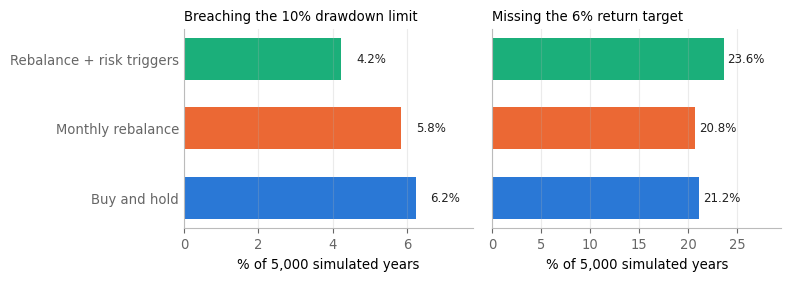

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 2.9), sharey=True)
panels = [("Chance of breaching 10% drawdown (%)", "Breaching the 10% drawdown limit"),
          ("Chance of missing 6% target (%)", "Missing the 6% return target")]
for ax, (column, title) in zip(axes, panels):
    chances = simulation_summary[column]
    rows = np.arange(len(POLICIES))
    ax.barh(rows, chances, color=[POLICY_COLORS[policy] for policy in POLICIES], height=0.6)
    for row, chance in enumerate(chances):
        ax.text(chance + 0.4, row, f"{chance:.1f}%", va="center", fontsize=8.5, color=TEXT_COLOR)
    ax.set_yticks(rows, POLICIES)
    ax.invert_yaxis()
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, chances.max() * 1.25)
    ax.grid(axis="x", alpha=0.25)
    ax.set_title(title, loc="left", fontsize=9.5)
    ax.set_xlabel(f"% of {N_SIMULATED_YEARS:,} simulated years")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "s2_fig_mc.pdf", bbox_inches="tight")
plt.show()

## 3. Rate scenarios: true vs estimated sensitivity

The synthetic data has an advantage real data never has: the true rate sensitivities are known (third value in `SECTOR_PARAMS`).
I compare them with the Stage 1 estimates, which rest on only 5 rate moves, and price two rate shocks on the client's allocation.
Market move held at zero to isolate the rate effect.

In [9]:
# Same regression as Stage 1
rate_change_in_25bp_steps = market["policy_rate_pct"].diff().fillna(0).to_numpy() / 0.25
regressors = np.column_stack([np.ones(len(market)), market["market_return_pct"], rate_change_in_25bp_steps])
estimated_sensitivity = np.array([np.linalg.lstsq(regressors, sector_returns[:, i], rcond=None)[0][2]
                                  for i in range(len(SECTORS))])
true_sensitivity = np.array([SECTOR_PARAMS[sector][2] for sector in SECTORS])

sensitivity_comparison = pd.DataFrame({"True (% per +25 bp)": true_sensitivity,
                                       "Estimated in Stage 1": estimated_sensitivity}, index=SECTORS)
sensitivity_comparison["Error"] = sensitivity_comparison["Estimated in Stage 1"] - sensitivity_comparison["True (% per +25 bp)"]
display(sensitivity_comparison.round(2))

sector_weights = TARGET_WEIGHTS[:len(SECTORS)]
rate_scenarios = {}
for scenario_name, rate_shock_bp in [("Rates +100 bp", 100), ("Rates -50 bp", -50)]:
    rate_scenarios[scenario_name] = {
        "Impact, true model (%)": (sector_weights * true_sensitivity).sum() * rate_shock_bp / 25,
        "Impact, Stage 1 estimate (%)": (sector_weights * estimated_sensitivity).sum() * rate_shock_bp / 25,
    }
rate_scenarios = pd.DataFrame(rate_scenarios).T
rate_scenarios.round(2)

,True (% per +25 bp),Estimated in Stage 1,Error
Technology,-0.8,0.07,0.87
Healthcare,-0.1,0.23,0.33
Financials,0.6,0.90,0.30
Energy,0.3,0.38,0.08
Renewable Energy,-1.0,-0.23,0.77
Real Estate,-0.9,-0.46,0.44


,"Impact, true model (%)","Impact, Stage 1 estimate (%)"
Rates +100 bp,-1.90,0.27
Rates -50 bp,0.95,-0.14


In [10]:
table_lines = [r"\begin{tabular}{@{}lrrr@{}}", r"\toprule",
               r"\textbf{Sector} & \textbf{True} & \textbf{Estimated (Stage 1)} & \textbf{Error} \\", r"\midrule"]
for sector, row in sensitivity_comparison.iterrows():
    cells = [to_latex_number(row["True (% per +25 bp)"], "{:.2f}", show_sign=True) + r"\%",
             to_latex_number(row["Estimated in Stage 1"], "{:.2f}", show_sign=True) + r"\%",
             to_latex_number(row["Error"], "{:.2f}", show_sign=True)]
    table_lines.append(f"{sector} & " + " & ".join(cells) + r" \\")
table_lines.append(r"\midrule")
for scenario_name, row in rate_scenarios.iterrows():
    cells = [to_latex_number(row["Impact, true model (%)"], "{:.2f}", show_sign=True) + r"\%",
             to_latex_number(row["Impact, Stage 1 estimate (%)"], "{:.2f}", show_sign=True) + r"\%"]
    table_lines.append(r"\textit{Portfolio: " + scenario_name + "} & " + " & ".join(cells) + r" & \\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
latex_table = "\n".join(table_lines)
(FIGURES_DIR / "s2_table_rates.tex").write_text(latex_table)
print(latex_table)

\begin{tabular}{@{}lrrr@{}}
\toprule
\textbf{Sector} & \textbf{True} & \textbf{Estimated (Stage 1)} & \textbf{Error} \\
\midrule
Technology & \textminus{}0.80\% & +0.07\% & +0.87 \\
Healthcare & \textminus{}0.10\% & +0.23\% & +0.33 \\
Financials & +0.60\% & +0.90\% & +0.30 \\
Energy & +0.30\% & +0.38\% & +0.08 \\
Renewable Energy & \textminus{}1.00\% & \textminus{}0.23\% & +0.77 \\
Real Estate & \textminus{}0.90\% & \textminus{}0.46\% & +0.44 \\
\midrule
\textit{Portfolio: Rates +100 bp} & \textminus{}1.90\% & +0.27\% & \\
\textit{Portfolio: Rates -50 bp} & +0.95\% & \textminus{}0.14\% & \\
\bottomrule
\end{tabular}


## Key findings (generated from the results above)

In [11]:
buy_and_hold = simulation_summary.loc["Buy and hold"]
monthly_rebalance = simulation_summary.loc["Monthly rebalance"]
with_triggers = simulation_summary.loc["Rebalance + risk triggers"]
rate_shock = rate_scenarios.loc["Rates +100 bp"]
breach, median_return, miss_target = ("Chance of breaching 10% drawdown (%)", "Median return (%)",
                                      "Chance of missing 6% target (%)")
findings = [
    "Replay of the actual year: "
    + ", ".join(f"{policy} {replay_summary.loc[policy, 'Return (%)']:+.1f}%" for policy in POLICIES) + ".",
    f"Across 5,000 years, the chance of breaching the 10% drawdown limit is {buy_and_hold[breach]:.1f}% (buy and hold), "
    f"{monthly_rebalance[breach]:.1f}% (monthly rebalance) and {with_triggers[breach]:.1f}% (with risk triggers).",
    f"Median return: {buy_and_hold[median_return]:+.1f}% / {monthly_rebalance[median_return]:+.1f}% / "
    f"{with_triggers[median_return]:+.1f}%; chance of missing the 6% target: "
    f"{buy_and_hold[miss_target]:.1f}% / {monthly_rebalance[miss_target]:.1f}% / {with_triggers[miss_target]:.1f}%.",
    f"A +100 bp rate shock costs {rate_shock['Impact, true model (%)']:+.2f}% with the true sensitivities but only "
    f"{rate_shock['Impact, Stage 1 estimate (%)']:+.2f}% with the Stage 1 estimates: one year of data understates the rate risk.",
]
for finding in findings:
    print("-", finding)
(FIGURES_DIR / "s2_findings.txt").write_text("\n".join(findings))

- Replay of the actual year: Buy and hold +16.3%, Monthly rebalance +16.3%, Rebalance + risk triggers +16.0%.
- Across 5,000 years, the chance of breaching the 10% drawdown limit is 6.2% (buy and hold), 5.8% (monthly rebalance) and 4.2% (with risk triggers).
- Median return: +13.3% / +13.3% / +12.2%; chance of missing the 6% target: 21.2% / 20.8% / 23.6%.
- A +100 bp rate shock costs -1.90% with the true sensitivities but only +0.27% with the Stage 1 estimates: one year of data understates the rate risk.


501